# RAPTOR 계층 요약

**이 노트북에서 할 일**

1. Ch 12에서 쓰던 문서 열두 건과 질문 여덟 개를 그대로 읽습니다.
2. 자료에 적힌 갈래 이름으로 문서를 세 묶음으로 나눕니다.
3. 갈래마다 원문을 모아 요약 하나씩 세 개를 만들어 둡니다.
4. 질문과 요약 셋의 거리를 재어 갈래 하나를 고릅니다.
5. 고른 갈래의 원문만 남겨 정답 문서의 자리를 셉니다.
6. 질문 하나만 바꿔 같은 차례를 다시 지납니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
서비스 요청은 일곱 번이고 임베딩 네 번과 답 모델 세 번입니다.
갈래가 셋이라 요약을 만드는 답 모델 요청이 세 번입니다.
임베딩은 문서 한 번과 요약 한 번과 질문 두 번입니다.

예상 비용은 미화 0.01달러 아래이고 읽어 오는 파일은 문서 파일과 질문 파일 둘입니다.
새로 쓰는 파일은 없고 실행 시간은 2분 안팎입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절부터 9절까지 읽습니다.
Ch 12 검색 부품을 준비하고 갈래로 묶어 요약을 만들어 두는 자리입니다.
10절과 11절은 요약 층에서 갈래를 고르고 원문 층으로 내려가는 자리입니다.
12절부터 14절까지는 질문을 바꿔 보고 네 실행을 표로 보는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

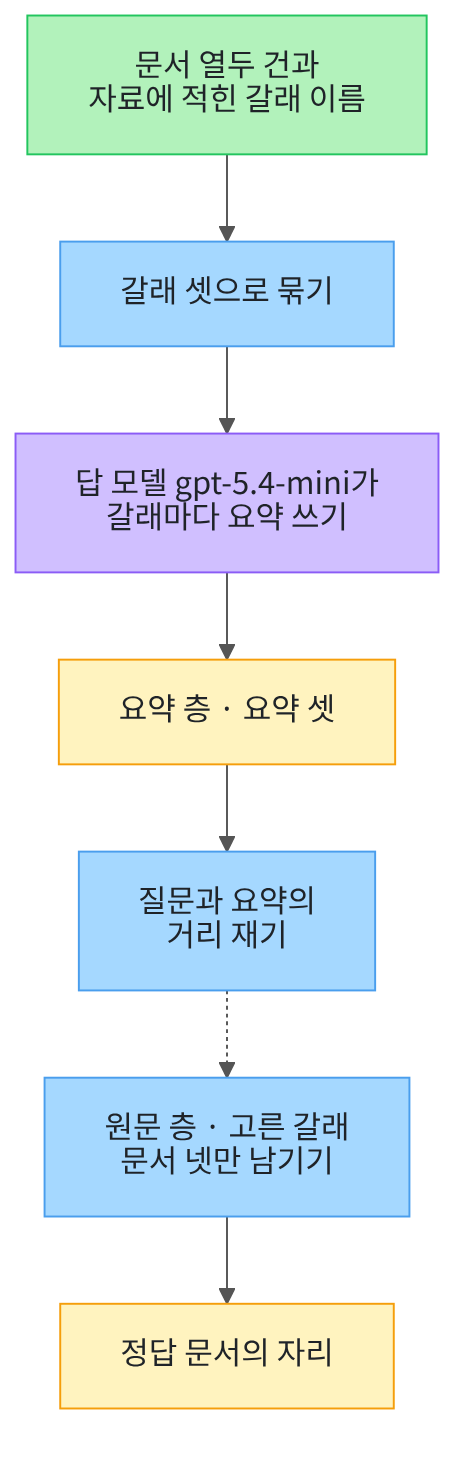

위에서 아래로 읽습니다.
맨 위 초록 상자가 자료에 있는 문서와 갈래 이름입니다.
파란 상자 셋은 우리가 코드로 적은 처리이고 보라 상자 하나가 요약을 쓴 모델입니다.
노란 상자 둘은 출력으로 확인한 값입니다.
점선은 가장 가까운 갈래 하나만 고르는 자리입니다.

## 1. 준비

첫 셀은 패키지 세 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3


**결과 읽기** — 설치가 끝나면 판 번호 세 줄이 보입니다.
이 노트북의 출력은 2026-09-19에 이 판으로 실행한 결과입니다.

다음 셀은 이름 다섯 개를 불러옵니다.
앞의 셋은 자료 읽기와 제곱근과 폴더 확인에 씁니다.
뒤의 둘은 Ch 9~13에서 쓴 임베딩과 답 모델 이름입니다.

In [2]:
# 자료 읽기·제곱근·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import math
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model

print("불러온 이름:", "json", "math", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json math os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 다섯 개가 보입니다.
이름 `OpenAIEmbeddings`와 `init_chat_model`은 07절에서 쓴 것과 같습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-19에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~07절과 같은 문서 파일과 질문 파일을 읽습니다.
두 파일은 Ch 12 core 벌 파일과 바이트가 같은 사본입니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
Ch 10~13과 01~07절에서 쓴 코드와 같습니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 Ch 12 core 벌 그대로입니다.
문서는 도서관 안내 열두 건입니다.

문서마다 제목과 본문 말고 갈래 이름이 적힌 칸이 하나 더 있습니다.
이 절은 그 칸을 써서 문서를 묶습니다.

## 4. 앞 절 부품 준비

다음 다섯 셀은 01~07절에서 이미 읽은 코드입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
첫 셀은 Ch 12에서 정한 값 셋을 적고 문서 글과 갈래 이름을 따로 모읍니다.
둘째 셀은 문서 ID로 원문과 갈래를 찾을 짝 둘을 만듭니다.
나머지 세 셀은 거리 함수 넷과 순위 함수 둘과 자리 세기 함수 둘입니다.

In [7]:
# Ch 12에서 쓴 값 셋을 그대로 적고 문서 12개의 제목·본문·갈래를 따로 모읍니다
similarity_top = 1
top_three = 3
top_all = 12
doc_texts = []
doc_ids = []
doc_categories = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
    doc_categories.append(doc["category"])
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("이어 붙인 글 수:", len(doc_texts))

코사인 유사도의 가장 큰 값: 1
나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
이어 붙인 글 수: 12


In [8]:
# 문서 ID로 원문과 갈래 이름을 찾을 짝 둘을 만듭니다
text_by_doc = {}
category_by_doc = {}
for i in range(len(doc_ids)):
    text_by_doc[doc_ids[i]] = doc_texts[i]
    category_by_doc[doc_ids[i]] = doc_categories[i]
print("짝의 수:", len(text_by_doc))
print("문서 LIB-001의 갈래:", category_by_doc["LIB-001"])

짝의 수: 12
문서 LIB-001의 갈래: library


In [9]:
# Ch 12 01절 점곱·길이·코사인 유사도·코사인 거리를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product


def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity

In [10]:
# Ch 12 05절 거리 순위 만들기와 순위 목록 출력 함수를 같은 코드로 다시 정의합니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(doc_ids)):
        distance = cosine_distance(question_vector, doc_vectors[i])
        pairs.append((distance, doc_ids[i]))
    hit_list = []
    # sorted(목록)는 튜플의 첫 값인 거리를 작은 값부터 정렬합니다
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]


def print_ranked(hit_list, value_name):
    print("순위 | 문서 ID |", value_name)
    for rank_number in range(len(hit_list)):
        row = hit_list[rank_number]
        print(rank_number + 1, "|", row["doc_id"], "|", row[value_name])

In [11]:
# Ch 11 01절 문서 ID 모으기와 정답 자리 세기를 같은 코드로 다시 정의합니다
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids


def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

준비 셀 다섯 개를 지났습니다.
02·03절이 쓴 순위 합치기 함수 둘은 04~07절에 이어 이 절에도 없습니다.
이 절도 목록 여러 개를 하나로 합치지 않기 때문입니다.
07절 점수 함수 다섯도 가져오지 않았습니다.
이 절은 점수를 매기지 않고 거리만 봅니다.

## 5. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [12]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 07절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 6. 갈래로 묶기

자료의 문서마다 갈래 이름이 칸 하나에 적혀 있습니다.
그 이름을 차례로 모아 갈래 목록을 만듭니다.
갈래마다 빈 목록을 하나 두고 문서 ID를 담습니다.
갈래를 모델이나 자동 묶기로 새로 만들지 않습니다.

In [13]:
# 자료에 적힌 갈래 이름을 차례로 모으고 갈래마다 문서 ID 목록을 만듭니다
category_names = []
doc_ids_by_category = {}
for i in range(len(doc_ids)):
    name = doc_categories[i]
    if name not in category_names:
        category_names.append(name)
        doc_ids_by_category[name] = []
    doc_ids_by_category[name].append(doc_ids[i])
print("갈래 이름:", category_names)

갈래 이름: ['library', 'facility', 'account']


**결과 읽기** — 출력 줄 `갈래 이름: ['library', 'facility', 'account']`가 자료에 적힌 갈래 셋입니다.
갈래를 우리가 정한 것이 아니라 자료에 이미 있던 것입니다.

빈 목록을 먼저 만들고 이름이 목록에 없을 때만 새로 담습니다.
갈래 이름은 자료에 나온 차례 그대로입니다.

다음 셀은 갈래마다 담긴 문서 ID를 봅니다.

In [14]:
# 갈래마다 담긴 문서 ID를 한 줄씩 봅니다
print("갈래 | 문서 ID")
for name in category_names:
    print(name, "|", doc_ids_by_category[name])

갈래 | 문서 ID
library | ['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004']
facility | ['FAC-001', 'FAC-002', 'FAC-003', 'FAC-004']
account | ['ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


**결과 읽기** — 라벨 줄 `갈래 | 문서 ID` 아래 세 줄에 갈래마다 문서 네 건이 담겼습니다.
첫 줄은 `library | ['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004']`입니다.

문서 ID의 앞 세 글자가 갈래와 짝지어 있습니다.

다음 셀은 만들 요약 수를 값으로 적어 둡니다.

In [15]:
# 갈래가 셋이라 만들 요약도 셋이라고 값으로 적어 둡니다
summary_count = 3
print("만들 요약 수:", summary_count)
print("자료에서 센 갈래 수:", len(category_names))
assert len(category_names) == summary_count, "갈래 수와 만들 요약 수가 다릅니다."

만들 요약 수: 3
자료에서 센 갈래 수: 3


**결과 읽기** — 출력 줄 `만들 요약 수: 3`이 이 절에서 만들 요약 수입니다.
출력 줄 `자료에서 센 갈래 수: 3`이 앞 셀에서 센 갈래 수입니다.
`assert` 한 줄이 두 값을 견줍니다.

요약 하나에 모델 요청이 한 번 듭니다.
그래서 요약 수를 값으로 적어 두면 요청 수를 미리 셀 수 있습니다.

## 7. 요약 머리글과 함수

요약을 만들려면 갈래 하나의 원문을 한 글로 모아야 합니다.
머리글 두 줄로 두 문장만 쓰고 새 내용을 보태지 말라고 적습니다.

In [16]:
# 요약 머리글 두 줄을 적고 갈래 하나의 원문을 그 뒤에 이어 붙입니다
summary_head = "아래 안내문의 공통 주제를 두 문장으로 요약하세요.\n"
summary_head = summary_head + "안내문에 있는 내용만 쓰고 새 내용을 보태지 마세요.\n\n"


def build_summary_prompt(category_name):
    material = ""
    for doc_id in doc_ids_by_category[category_name]:
        material = material + "[" + doc_id + "] " + text_by_doc[doc_id] + "\n"
    prompt_text = summary_head + "갈래: " + category_name + "\n안내문:\n" + material
    return prompt_text

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `build_summary_prompt`는 갈래 이름 하나를 받습니다.
그 갈래의 문서 ID를 차례로 보며 대괄호와 원문을 이어 붙입니다.
머리글 뒤에 갈래 이름과 그 글 덩어리를 붙여 한 글로 만듭니다.

## 8. 갈래마다 요약 만들기

다음 셀은 갈래 셋을 차례로 돌며 요약을 하나씩 받습니다.
질문을 받기 전에 미리 해 두는 일입니다.
모델을 몇 번 불렀는지 같은 셀에서 세어 둡니다.

In [17]:
# 갈래마다 요약 하나를 만들고 모델을 몇 번 불렀는지 함께 셉니다(모델 요청 3번)
summary_texts = []
summary_calls = 0
for name in category_names:
    summary_prompt = build_summary_prompt(name)
    summary_reply = model.invoke(summary_prompt)
    summary_texts.append(summary_reply.text.strip())
    summary_calls = summary_calls + 1
print("만든 요약 수:", len(summary_texts))
print("부른 모델 요청 수:", summary_calls)

만든 요약 수: 3
부른 모델 요청 수: 3


**결과 읽기** — 출력 줄 `만든 요약 수: 3`으로 갈래마다 요약 하나를 받았습니다.
출력 줄 `부른 모델 요청 수: 3`이 이 셀에서 보낸 요청 수입니다.

요약은 갈래 목록과 같은 차례로 담깁니다.
요약 글은 모델이 쓴 글이라 실행마다 문장이 달라질 수 있습니다.
그래서 요약 글 자체에는 `assert`를 걸지 않았습니다.

다음 셀은 만든 요약을 눈으로 봅니다.

In [18]:
# 만든 요약 셋을 갈래 이름·글자 수와 함께 한 줄씩 봅니다
print("갈래 | 요약 글자 수")
for i in range(len(summary_texts)):
    print(category_names[i], "|", len(summary_texts[i]))
print("갈래별 요약 글:")
for i in range(len(summary_texts)):
    print(category_names[i], "|", summary_texts[i])

갈래 | 요약 글자 수
library | 85
facility | 105
account | 81
갈래별 요약 글:
library | 도서관에서는 일반 도서와 전자책의 대출 기간과 연장, 대출 제한 규정을 안내합니다.  
또한 희망 도서 신청 방법과 전자책 이용 방법도 함께 안내합니다.
facility | 안내문들은 스터디룸 예약, 프린터 이용, 운영 시간, 분실물 보관처럼 시설 이용과 관련된 내용을 안내합니다. 각 시설의 이용 방법, 시간, 비용, 보관 기간 같은 이용 규칙을 알려 줍니다.
account | 안내문들은 계정과 이용 권한에 관한 내용을 다룹니다. 비밀번호 재설정, 학생증 분실 처리, 휴학생과 졸업생의 이용 가능 범위가 안내되어 있습니다.


**결과 읽기** — 라벨 줄 `갈래 | 요약 글자 수` 아래 세 줄에 갈래별 글자 수가 있습니다.
라벨 줄 `갈래별 요약 글:` 아래 세 줄이 모델이 쓴 요약입니다.

글자 수와 문장은 실행마다 달라집니다.
탐색 실행에서 `library` 갈래 요약이 여든두 자에서 백예순 자까지 오갔습니다.
그래서 이 값들은 이 절의 결론과 그림 라벨에 넣지 않았습니다.

## 9. 요약을 벡터로 바꾸기

요약으로 찾으려면 요약도 벡터로 바꿔야 합니다.
문서와 같은 모델과 같은 숫자 개수를 씁니다.

In [19]:
# 요약 셋을 문서와 같은 모델로 벡터로 바꿉니다(임베딩 요청 1번)
summary_vectors = embedding_model.embed_documents(summary_texts)
print("요약 벡터 수:", len(summary_vectors))
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)

요약 벡터 수: 3
벡터의 숫자 개수 설정: 256


**결과 읽기** — 출력 줄 `요약 벡터 수: 3`으로 요약마다 벡터 하나를 받았습니다.
출력 줄 `벡터의 숫자 개수 설정: 256`이 문서를 바꿀 때와 같습니다.

같은 모델과 같은 숫자 개수를 써야 거리를 견줄 수 있습니다.
요약 벡터는 질문을 받기 전에 한 번만 만들어 둡니다.

## 10. 요약 층에서 갈래 고르기

이제 질문을 받습니다.
먼저 질문과 요약 셋의 거리를 재는 함수를 만듭니다.

In [20]:
# 질문과 요약 셋의 거리를 재어 가까운 갈래부터 늘어놓습니다
def rank_summaries(question_vector):
    pairs = []
    for i in range(len(category_names)):
        distance = cosine_distance(question_vector, summary_vectors[i])
        pairs.append((distance, category_names[i]))
    row_list = []
    for pair in sorted(pairs):
        row_list.append({"갈래": pair[1], "거리": round(pair[0], 2)})
    return row_list

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `rank_summaries`는 질문 벡터 하나를 받습니다.
요약 셋과의 코사인 거리를 재어 가까운 갈래부터 늘어놓습니다.
문서가 아니라 갈래 이름을 담는다는 점이 `rank_by_distance`와 다릅니다.

다음 셀은 첫 질문을 정하고 그 함수를 부릅니다.

In [21]:
# 첫 질문을 정하고 요약 층에서 갈래마다 거리를 잽니다(임베딩 요청 1번)
question = "비밀번호를 잊었을 때 받는 재설정 링크는 얼마 동안 쓸 수 있나요?"
gold_doc_id = "ACC-001"
question_vector = embedding_model.embed_query(question)
summary_rows = rank_summaries(question_vector)
print("고른 질문:", question)
print("이 질문의 정답 문서 ID:", gold_doc_id)
print("순위 | 갈래 | 거리")
for rank_number in range(len(summary_rows)):
    print(rank_number + 1, "|", summary_rows[rank_number]["갈래"], "|", summary_rows[rank_number]["거리"])

고른 질문: 비밀번호를 잊었을 때 받는 재설정 링크는 얼마 동안 쓸 수 있나요?
이 질문의 정답 문서 ID: ACC-001
순위 | 갈래 | 거리
1 | account | 0.6
2 | facility | 0.78
3 | library | 0.86


**결과 읽기** — 출력 줄 `이 질문의 정답 문서 ID: ACC-001`이 이 물음의 정답 문서입니다.
라벨 줄 `순위 | 갈래 | 거리` 아래 세 줄이 요약 층의 거리 순위입니다.
첫 줄의 갈래가 질문과 가장 가까운 요약의 갈래입니다.

거리 값은 요약 글에 따라 달라집니다.
요약 글이 실행마다 바뀌므로 이 세 값은 결론에 넣지 않습니다.

다음 셀은 첫 줄의 갈래 하나를 고릅니다.

In [22]:
# 거리가 가장 가까운 갈래 하나를 골라 그 갈래의 문서를 봅니다
chosen_category = summary_rows[0]["갈래"]
chosen_doc_ids = doc_ids_by_category[chosen_category]
print("고른 갈래:", chosen_category)
print("그 갈래의 문서:", chosen_doc_ids)
print("그 갈래의 문서 수:", len(chosen_doc_ids))
print("정답 문서가 고른 갈래 안에 있는가:", gold_doc_id in chosen_doc_ids)

고른 갈래: account
그 갈래의 문서: ['ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']
그 갈래의 문서 수: 4
정답 문서가 고른 갈래 안에 있는가: True


**결과 읽기** — 출력 줄 `고른 갈래: account`가 요약 층이 고른 갈래입니다.
출력 줄 `그 갈래의 문서 수: 4`로 원문 층에서 볼 문서가 넷으로 줄었습니다.
출력 줄 `정답 문서가 고른 갈래 안에 있는가: True`로 정답 문서가 그 안에 있습니다.

기준값과 견주지 않고 가장 가까운 갈래 하나를 그대로 고릅니다.
06절과 07절은 기준값을 두었지만 이 절에는 견줄 기준값이 없습니다.

## 11. 원문 층으로 내려가기

고른 갈래의 원문만 남기려면 순위 목록을 거르는 함수가 필요합니다.
문서 ID로 갈래를 찾는 짝을 앞에서 만들어 두었습니다.

In [23]:
# 순위 목록에서 고른 갈래의 문서만 남깁니다
def keep_category(hit_list, category_name):
    kept = []
    for hit in hit_list:
        if category_by_doc[hit["doc_id"]] == category_name:
            kept.append(hit)
    return kept

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `keep_category`는 순위 목록과 갈래 이름 하나를 받습니다.
목록을 차례로 보며 갈래가 같은 문서만 새 목록에 담습니다.
거리 순서는 그대로 두고 덜어 내기만 합니다.

다음 셀은 먼저 원문 열두 건을 바로 검색해 견줄 값을 만듭니다.

In [24]:
# 요약 층을 거치지 않고 원문 열두 건을 바로 검색해 봅니다(임베딩 요청 0번)
base_hits = rank_by_distance(question_vector, top_all)
base_ids = unique_doc_ids(base_hits)
base_place = find_gold_rank(base_ids, [gold_doc_id])
print("본 문서 수:", len(base_ids))
print("정답 문서의 자리:", base_place)
print_ranked(base_hits[:top_three], "거리")

본 문서 수: 12
정답 문서의 자리: 1
순위 | 문서 ID | 거리
1 | ACC-001 | 0.16
2 | ACC-003 | 0.61
3 | FAC-004 | 0.68


**결과 읽기** — 출력 줄 `본 문서 수: 12`로 문서 열두 건을 모두 재었습니다.
출력 줄 `정답 문서의 자리: 1`로 정답 문서가 맨 앞에 섰습니다.
순위 표 첫 줄은 `1 | ACC-001 | 0.16`입니다.

이 값이 요약 층을 거치지 않았을 때의 결과입니다.
Ch 12에서 하던 검색 한 번과 같습니다.

다음 셀은 같은 순위 목록에서 고른 갈래만 남깁니다.

In [25]:
# 같은 순위 목록에서 고른 갈래의 원문만 남겨 자리를 다시 셉니다
leaf_hits = keep_category(base_hits, chosen_category)
leaf_ids = unique_doc_ids(leaf_hits)
leaf_place = find_gold_rank(leaf_ids, [gold_doc_id])
print("본 문서 수:", len(leaf_ids))
print("정답 문서의 자리:", leaf_place)
print_ranked(leaf_hits[:top_three], "거리")

본 문서 수: 4
정답 문서의 자리: 1
순위 | 문서 ID | 거리
1 | ACC-001 | 0.16
2 | ACC-003 | 0.61
3 | ACC-004 | 0.76


**결과 읽기** — 출력 줄 `본 문서 수: 4`로 볼 문서가 열둘에서 넷으로 줄었습니다.
출력 줄 `정답 문서의 자리: 1`은 앞 셀과 같습니다.
순위 표 첫 줄도 `1 | ACC-001 | 0.16`으로 같습니다.

이 질문에서는 자리가 달라지지 않았습니다.
달라진 것은 자리를 셀 때 본 문서 수입니다.

## 12. 값 바꿔 보기 · 질문 하나만 바꾸기

바꿀 것은 질문 하나입니다.
요약 셋과 갈래 묶음과 문서 벡터는 그대로 둡니다.
실행 전에 예상해 봅니다.
바꾼 질문은 책을 빌리는 일을 묻지만 정답은 졸업생 안내문입니다.

In [26]:
# 바꿀 것은 질문 하나이고 요약 셋과 갈래 묶음은 그대로 둡니다(임베딩 요청 1번)
other_question = "졸업한 뒤에는 책을 몇 권까지 빌릴 수 있나요?"
other_gold_doc_id = "ACC-004"
other_vector = embedding_model.embed_query(other_question)
other_rows = rank_summaries(other_vector)
other_category = other_rows[0]["갈래"]
other_doc_ids = doc_ids_by_category[other_category]
print("바꾼 질문:", other_question)
print("이 질문의 정답 문서 ID:", other_gold_doc_id)
print("고른 갈래:", other_category)
print("정답 문서가 고른 갈래 안에 있는가:", other_gold_doc_id in other_doc_ids)

바꾼 질문: 졸업한 뒤에는 책을 몇 권까지 빌릴 수 있나요?
이 질문의 정답 문서 ID: ACC-004
고른 갈래: library
정답 문서가 고른 갈래 안에 있는가: False


**결과 읽기** — 출력 줄 `이 질문의 정답 문서 ID: ACC-004`가 이 물음의 정답 문서입니다.
출력 줄 `고른 갈래: library`로 요약 층이 도서 갈래를 골랐습니다.
출력 줄 `정답 문서가 고른 갈래 안에 있는가: False`가 이 절에서 볼 자리입니다.

질문에 「책」과 「빌리다」가 있어 도서 갈래 요약과 더 가까웠습니다.
정답 문서는 계정 갈래에 있는 졸업생 안내문입니다.

다음 셀은 두 층의 결과를 나란히 봅니다.

In [27]:
# 바꾼 질문으로 원문 열두 건과 고른 갈래 원문을 나란히 검색합니다
other_hits = rank_by_distance(other_vector, top_all)
other_base_ids = unique_doc_ids(other_hits)
other_base_place = find_gold_rank(other_base_ids, [other_gold_doc_id])
other_leaf_hits = keep_category(other_hits, other_category)
other_leaf_ids = unique_doc_ids(other_leaf_hits)
other_leaf_place = find_gold_rank(other_leaf_ids, [other_gold_doc_id])
print("원문 열두 건을 바로 검색한 자리:", other_base_place)
print("고른 갈래 원문만 남겨 센 자리:", other_leaf_place)
print("고른 갈래에서 본 문서:", other_leaf_ids)

원문 열두 건을 바로 검색한 자리: 1
고른 갈래 원문만 남겨 센 자리: 0
고른 갈래에서 본 문서: ['LIB-004', 'LIB-001', 'LIB-003', 'LIB-002']


**결과 읽기** — 출력 줄 `원문 열두 건을 바로 검색한 자리: 1`로 정답 문서가 맨 앞이었습니다.
출력 줄 `고른 갈래 원문만 남겨 센 자리: 0`에서 영은 목록 안에 없다는 뜻입니다.
출력 줄 `고른 갈래에서 본 문서` 뒤 목록에 정답 문서가 없습니다.

요약 층이 다른 갈래를 고르면 원문 층에서 정답 문서를 만나지 못합니다.
원문을 모두 재면 맨 앞에 설 문서였는데도 후보에 들어오지 않았습니다.

## 13. 요약 수 확인

요약을 만들 때마다 모델 요청이 늘어납니다.
값으로 적어 둔 수와 실제 수를 나란히 봅니다.

In [28]:
# 값으로 적어 둔 요약 수와 실제로 만든 수·부른 요청 수를 나란히 봅니다
print("값으로 적어 둔 요약 수:", summary_count)
print("실제로 만든 요약 수:", len(summary_texts))
print("요약에 부른 모델 요청 수:", summary_calls)
assert len(summary_texts) == summary_count, "만든 요약 수가 적어 둔 값과 다릅니다."
assert summary_calls == summary_count, "부른 요청 수가 적어 둔 값과 다릅니다."

값으로 적어 둔 요약 수: 3
실제로 만든 요약 수: 3
요약에 부른 모델 요청 수: 3


**결과 읽기** — 출력 줄 `값으로 적어 둔 요약 수: 3`이 코드에 적어 둔 값입니다.
출력 줄 `실제로 만든 요약 수: 3`과 `요약에 부른 모델 요청 수: 3`이 그 값과 같습니다.

`assert` 두 줄은 이 세 값만 봅니다.
모델이 쓴 요약 글에는 `assert`를 걸지 않았습니다.

## 14. 네 실행을 기록 한 줄씩으로

실행 하나를 기록 한 줄로 만들어 담아 둡니다.
Ch 9~13과 01~07절에서 쓴 기록 한 줄과 같은 모양입니다.
칸은 이 절이 견주는 값으로 다시 짰습니다.
고른 갈래와 본 문서 수와 정답 문서의 자리 셋입니다.

In [29]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, chosen_name, seen_ids, place):
    row = {"실행": run_name}
    row["고른 갈래"] = chosen_name
    row["본 문서 수"] = len(seen_ids)
    row["정답 문서의 자리"] = place
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
담는 칸은 실행 이름과 고른 갈래와 본 문서 수와 정답 문서의 자리 넷입니다.
본 문서 수는 문서 ID 목록을 받아 함수 안에서 셉니다.
07절 기록 한 줄의 점수 칸과 고친 횟수 칸은 이 절에 없습니다.
이 절이 견주는 것이 답이 아니라 검색 결과이기 때문입니다.

다음 셀은 네 실행의 기록을 표로 출력합니다.

In [30]:
# 네 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("첫 질문 · 원문 열두 건", "고르지 않음", base_ids, base_place))
run_rows.append(run_row("첫 질문 · 요약으로 고른 갈래", chosen_category, leaf_ids, leaf_place))
run_rows.append(run_row("바꾼 질문 · 원문 열두 건", "고르지 않음", other_base_ids, other_base_place))
run_rows.append(run_row("바꾼 질문 · 요약으로 고른 갈래", other_category, other_leaf_ids, other_leaf_place))
print("실행 | 고른 갈래 | 본 문서 수 | 정답 문서의 자리")
for row in run_rows:
    print(row["실행"], "|", row["고른 갈래"], "|", row["본 문서 수"], "|", row["정답 문서의 자리"])

실행 | 고른 갈래 | 본 문서 수 | 정답 문서의 자리
첫 질문 · 원문 열두 건 | 고르지 않음 | 12 | 1
첫 질문 · 요약으로 고른 갈래 | account | 4 | 1
바꾼 질문 · 원문 열두 건 | 고르지 않음 | 12 | 1
바꾼 질문 · 요약으로 고른 갈래 | library | 4 | 0


**결과 읽기** — 라벨 줄 아래 첫 줄과 둘째 줄이 첫 질문의 두 실행입니다.
둘째 줄은 `첫 질문 · 요약으로 고른 갈래 | account | 4 | 1`입니다.
넷째 줄은 `바꾼 질문 · 요약으로 고른 갈래 | library | 4 | 0`입니다.

넷째 줄의 영은 고른 갈래 안에 정답 문서가 없었다는 뜻입니다.
셋째 줄을 보면 같은 질문도 원문을 모두 재면 자리가 하나였습니다.

## 정리

1. 자료에 적힌 갈래로 문서를 세 묶음으로 나누고 갈래마다 요약 하나를 미리 만들었습니다.
2. 질문과 요약 셋의 거리를 재어 갈래 하나를 고르고 그 갈래 원문만 보았습니다.
3. 첫 질문에서는 본 문서가 열둘에서 넷으로 줄었고 정답 문서의 자리는 그대로였습니다.
4. 바꾼 질문에서는 요약 층이 다른 갈래를 골라 정답 문서를 만나지 못했습니다.

09절에서는 이 챕터에서 본 패턴들을 같은 질문과 같은 정답으로 나란히 견줍니다.
이 절은 찾기 전에 자료 쪽을 묶어 두었고 09절은 패턴을 고르는 자리입니다.